<h1>04. Communities</h1>

Noa Yarin Levy | Jimi Halawi | Ofir Atias

**What we do.** We split the graph into Louvain communities and check how Web and Machine Learning developers are mixed inside them.

**What we get.** Community tables, community figures, and community features that can be used later.

**Why this step matters.** Communities show whether developers with similar labels tend to sit in the same parts of the graph.

In [1]:
from pathlib import Path
import os
import sys
import warnings

def _find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root")

ROOT = _find_project_root(Path.cwd())
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
__name__ = "notebook_04"
print(f"Project root: {ROOT}")

Project root: C:\Users\Jimi\Desktop\github-social-network


<h2>How we check communities</h2>

Louvain groups nodes that are more connected to each other than to the rest of the graph. We then check how large the groups are and whether each group is mostly Web, mostly Machine Learning, or mixed.

<h3>Table: <code>outputs/tables/community_metrics.csv</code></h3>

The Louvain community score and overall community measures.

In [5]:
community_metrics = pd.read_csv(ROOT / 'outputs/tables/community_metrics.csv')
display(community_metrics)

,number_of_communities,modularity,largest_community_size,median_community_size,size_weighted_mean_purity
0,31,0.453448,8732,9.0,0.829788


**Conclusion.** The graph is split into 31 communities, and the community score is high enough to show a clear grouping pattern.

<h3>Table: <code>outputs/tables/community_summary.csv</code></h3>

Size and label composition for every detected community.

In [6]:
communities = pd.read_csv(ROOT / 'outputs/tables/community_summary.csv')
display(communities.sort_values('size', ascending=False).head(12))

,community_id,size,web_count,ml_count,web_ratio,ml_ratio,dominant_label,purity
0,7,8732,8165,567,0.935066,0.064934,Web,0.935066
1,2,7664,2181,5483,0.284577,0.715423,ML,0.715423
2,13,6454,5205,1249,0.806477,0.193523,Web,0.806477
3,0,3047,2587,460,0.849032,0.150968,Web,0.849032
4,5,2702,2534,168,0.937824,0.062176,Web,0.937824
5,11,2396,1750,646,0.730384,0.269616,Web,0.730384
6,8,2087,1902,185,0.911356,0.088644,Web,0.911356
7,3,2000,1563,437,0.781500,0.218500,Web,0.781500
8,4,904,649,255,0.717920,0.282080,Web,0.717920
9,10,566,472,94,0.833922,0.166078,Web,0.833922


**Conclusion.** Large communities differ sharply in ML share, making community membership informative but not deterministic.

<h3>Figure: <code>community_size_and_composition.png</code></h3>

This figure jointly visualizes the sizes and target composition of the largest rows in the preceding table.

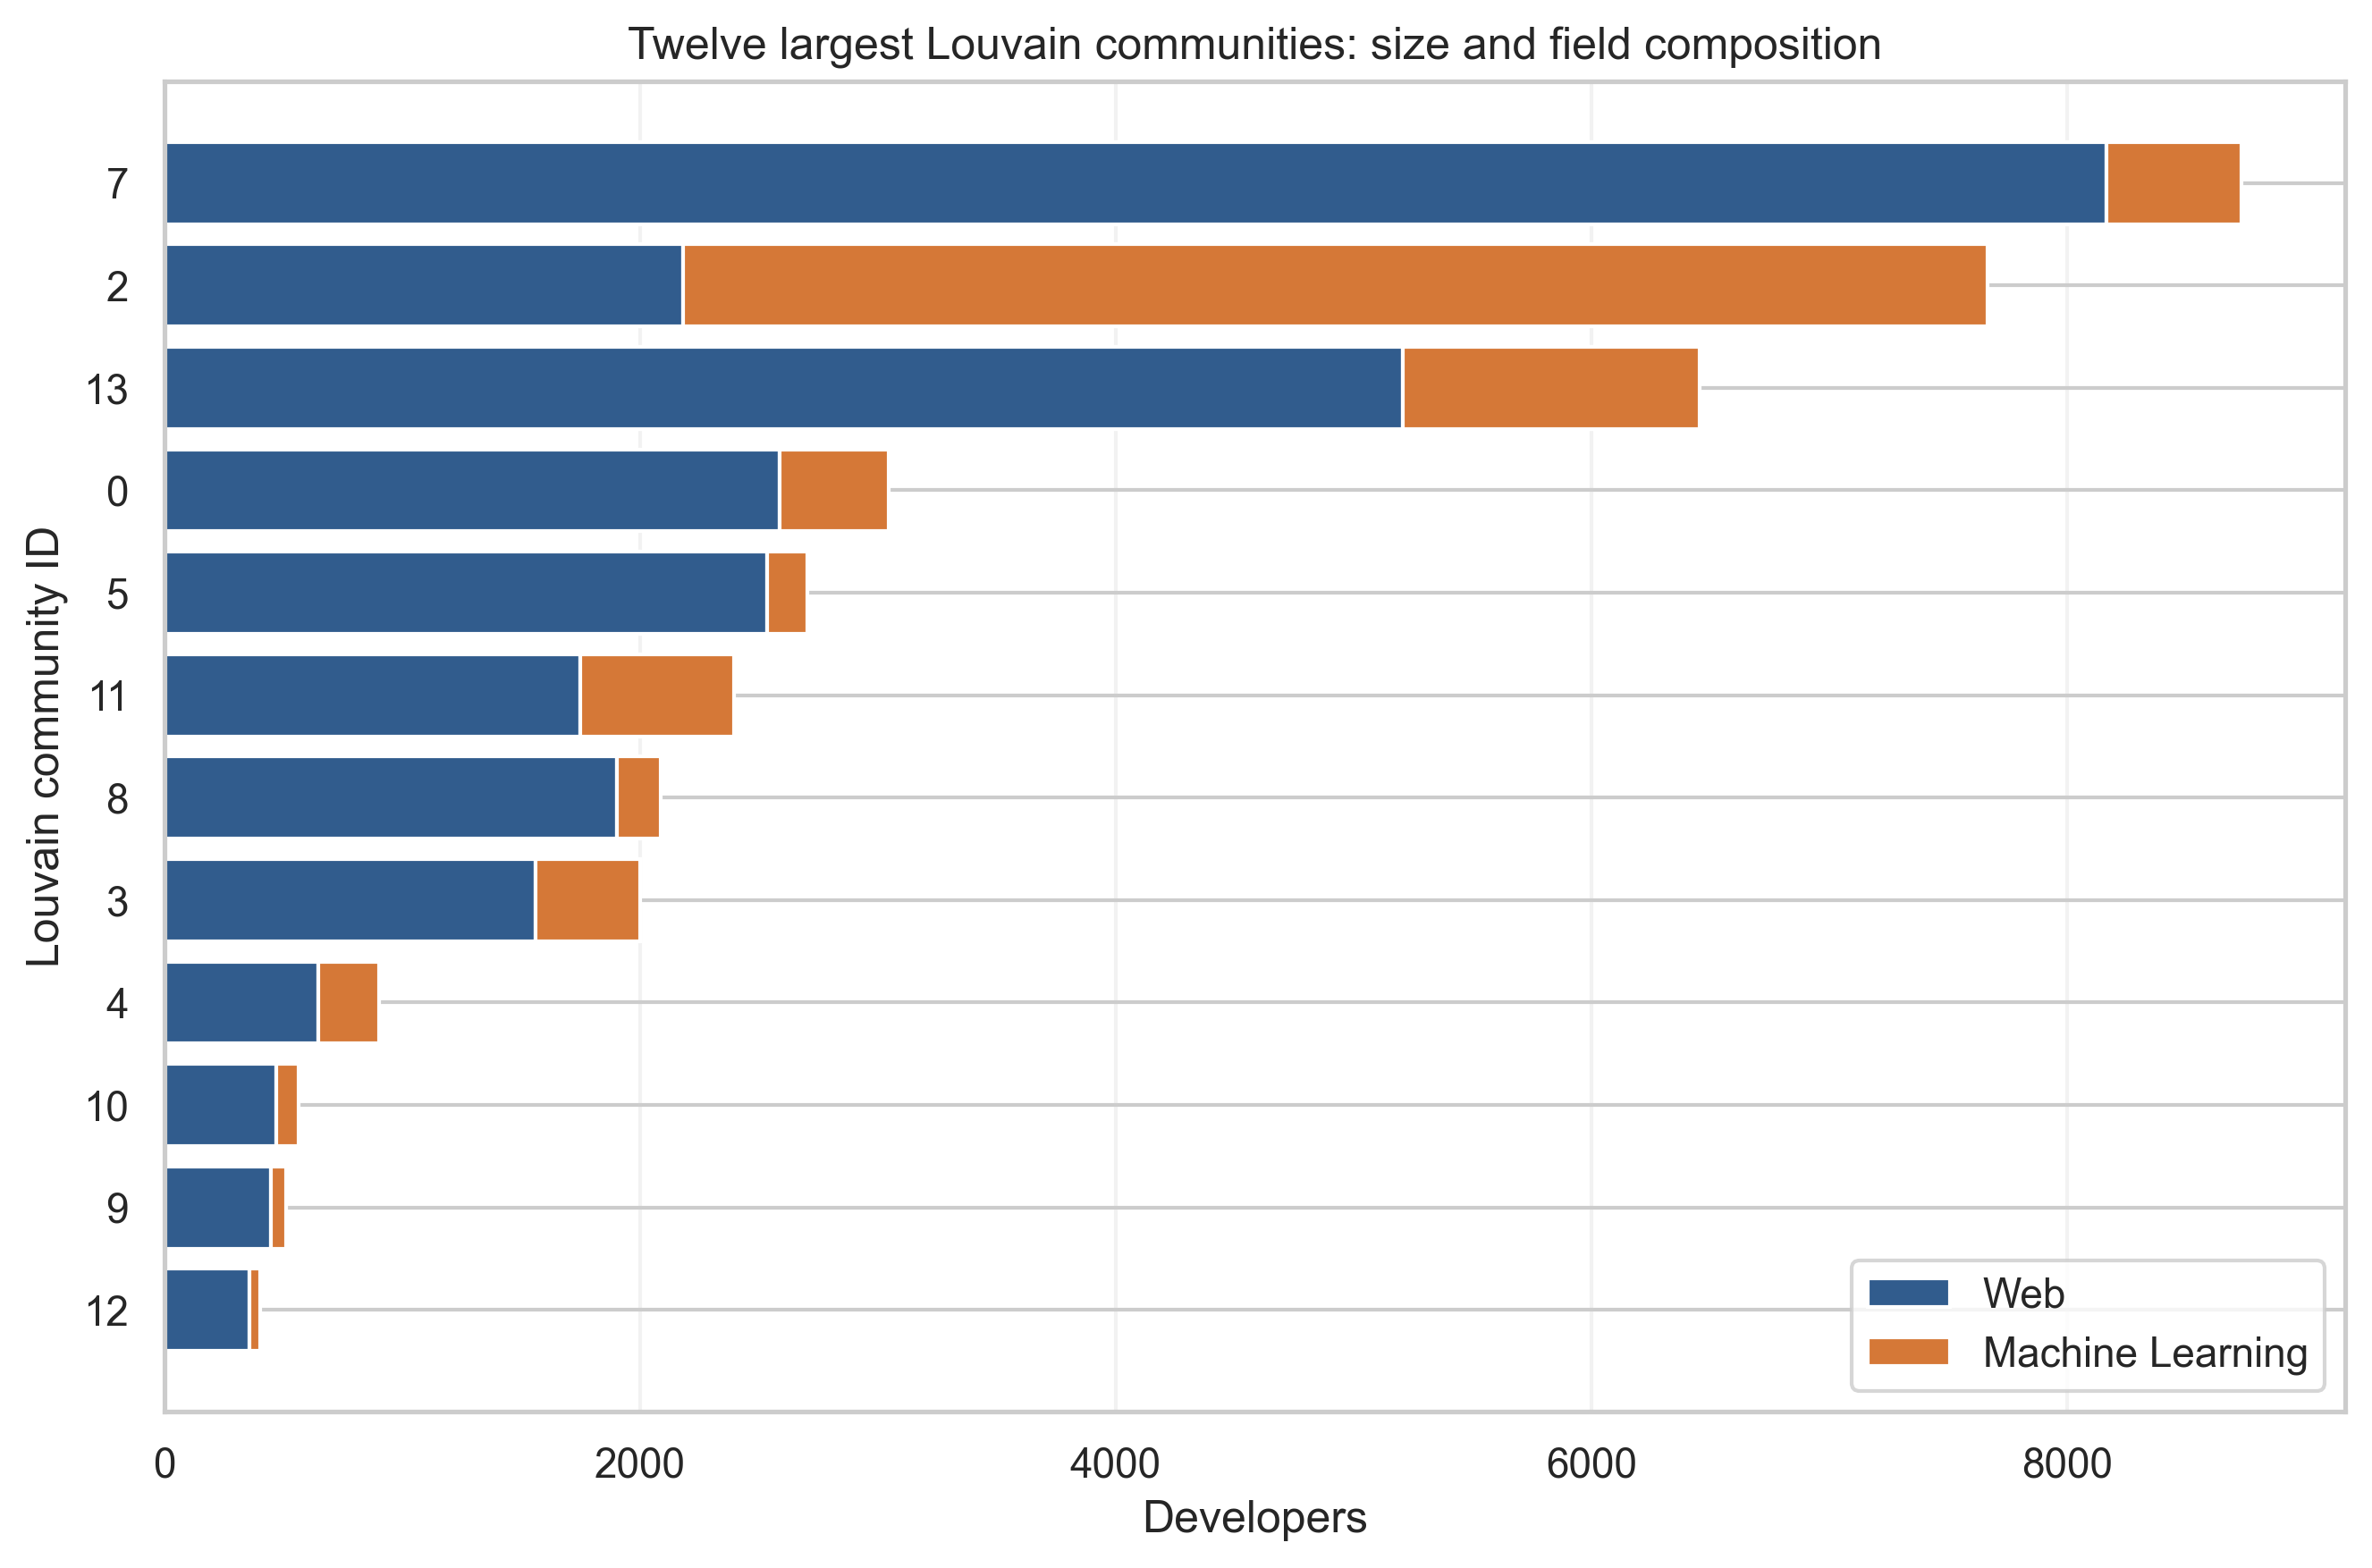

In [7]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/figures/community_size_and_composition.png')))

**Figure note.** The largest groups include both field-enriched and mixed communities, explaining why community features improve classification without producing perfect labels.

<h3>Main community takeaway</h3>

The three largest communities contain 8,732, 7,664, and 6,454 developers with markedly different ML shares. This preserves the original notebook's concrete composition comparison while keeping the computation in the numbered workflow.

<h2>Summary</h2>

In this notebook we grouped the network into Louvain communities. We checked the size of the communities and how mixed they are between Web and Machine Learning developers. The communities are useful because many of them have a clear label tendency, but they are not perfect. This gives us extra graph features to try in the classification notebook.